<a href="https://colab.research.google.com/github/oabdelhalim8/ML---2/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys

assert sys.version_info >= (3, 10)

In [2]:
from packaging.version import Version
import sklearn

assert Version(sklearn.__version__) >= Version("1.6.1")

In [3]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [4]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False)

In [5]:
# extra code – it's a bit too long
print(mnist.DESCR)

**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  
**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  
**Please cite**:  

The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  

It is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 image b

In [6]:
mnist.keys()  # extra code – we only use data and target in this notebook

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [7]:
mnist.categories

{'class': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']}

In [8]:
mnist.feature_names

['pixel1',
 'pixel2',
 'pixel3',
 'pixel4',
 'pixel5',
 'pixel6',
 'pixel7',
 'pixel8',
 'pixel9',
 'pixel10',
 'pixel11',
 'pixel12',
 'pixel13',
 'pixel14',
 'pixel15',
 'pixel16',
 'pixel17',
 'pixel18',
 'pixel19',
 'pixel20',
 'pixel21',
 'pixel22',
 'pixel23',
 'pixel24',
 'pixel25',
 'pixel26',
 'pixel27',
 'pixel28',
 'pixel29',
 'pixel30',
 'pixel31',
 'pixel32',
 'pixel33',
 'pixel34',
 'pixel35',
 'pixel36',
 'pixel37',
 'pixel38',
 'pixel39',
 'pixel40',
 'pixel41',
 'pixel42',
 'pixel43',
 'pixel44',
 'pixel45',
 'pixel46',
 'pixel47',
 'pixel48',
 'pixel49',
 'pixel50',
 'pixel51',
 'pixel52',
 'pixel53',
 'pixel54',
 'pixel55',
 'pixel56',
 'pixel57',
 'pixel58',
 'pixel59',
 'pixel60',
 'pixel61',
 'pixel62',
 'pixel63',
 'pixel64',
 'pixel65',
 'pixel66',
 'pixel67',
 'pixel68',
 'pixel69',
 'pixel70',
 'pixel71',
 'pixel72',
 'pixel73',
 'pixel74',
 'pixel75',
 'pixel76',
 'pixel77',
 'pixel78',
 'pixel79',
 'pixel80',
 'pixel81',
 'pixel82',
 'pixel83',
 'pixel84',
 

In [9]:
mnist.target_names

['class']

In [10]:
X, y = mnist.data, mnist.target
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [11]:
X.shape

(70000, 784)

In [12]:
y

array(['5', '0', '4', ..., '4', '5', '6'], dtype=object)

In [13]:
y.shape

(70000,)

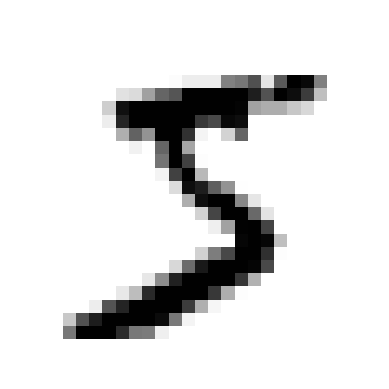

In [14]:
import matplotlib.pyplot as plt

def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="binary")
    plt.axis("off")

some_digit = X[0]
plot_digit(some_digit)

plt.show()

In [15]:
y[0]

'5'

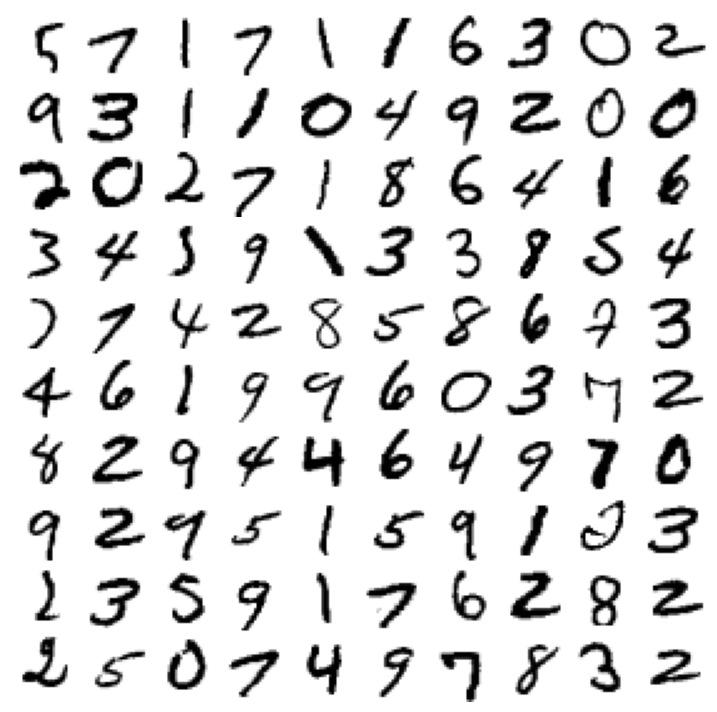

In [16]:
# extra code – this cell generates Figure 3–2
plt.figure(figsize=(9, 9))
for idx, image_data in enumerate(X[100:200]):
    plt.subplot(10, 10, idx + 1)
    plot_digit(image_data)
plt.subplots_adjust(wspace=0, hspace=0)

plt.show()

In [17]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

In [18]:
y_train_5 = (y_train == '5')  # True for all 5s, False for all other digits
y_test_5 = (y_test == '5')

In [19]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_5)

SGDClassifier(random_state=42)

In [20]:
sgd_clf.predict([some_digit])

array([ True])

In [21]:
from sklearn.model_selection import cross_val_score

cross_val_score(sgd_clf, X_train, y_train_5, cv=3, scoring="accuracy")

array([0.95035, 0.96035, 0.9604 ])

In [22]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfolds = StratifiedKFold(n_splits=3)  # add shuffle=True if the dataset is
                                       # not already shuffled
for train_index, test_index in skfolds.split(X_train, y_train_5):
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_5[train_index]
    X_test_fold = X_train[test_index]
    y_test_fold = y_train_5[test_index]

    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_fold)
    n_correct = sum(y_pred == y_test_fold)
    print(n_correct / len(y_pred))

0.95035
0.96035
0.9604


In [23]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train_5)
print(any(dummy_clf.predict(X_train)))

False


In [24]:
cross_val_score(dummy_clf, X_train, y_train_5, cv=3, scoring="accuracy")

array([0.90965, 0.90965, 0.90965])

In [25]:
from sklearn.model_selection import cross_val_predict

y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3)

In [26]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_train_5, y_train_pred)
cm

array([[53892,   687],
       [ 1891,  3530]])

In [27]:
y_train_perfect_predictions = y_train_5  # pretend we reached perfection
confusion_matrix(y_train_5, y_train_perfect_predictions)

array([[54579,     0],
       [    0,  5421]])

In [28]:
from sklearn.metrics import precision_score, recall_score

precision_score(y_train_5, y_train_pred)  # == 3530 / (687 + 3530)

0.8370879772350012

In [29]:
# extra code – this cell also computes the precision: TP / (FP + TP)
cm[1, 1] / (cm[0, 1] + cm[1, 1])

np.float64(0.8370879772350012)

In [30]:
recall_score(y_train_5, y_train_pred)  # == 3530 / (1891 + 3530)

0.6511713705958311

In [31]:
# extra code – this cell also computes the recall: TP / (FN + TP)
cm[1, 1] / (cm[1, 0] + cm[1, 1])

np.float64(0.6511713705958311)

In [32]:
from sklearn.metrics import f1_score

f1_score(y_train_5, y_train_pred)

0.7325171197343847

In [33]:
# extra code – this cell also computes the f1 score
cm[1, 1] / (cm[1, 1] + (cm[1, 0] + cm[0, 1]) / 2)

np.float64(0.7325171197343847)

In [34]:
y_scores = sgd_clf.decision_function([some_digit])
y_scores

array([2164.22030239])

In [35]:
threshold = 0
y_some_digit_pred = (y_scores > threshold)

In [36]:
y_some_digit_pred

array([ True])

In [37]:
# extra code – just shows that y_scores > 0 produces the same result as
#              calling predict()
y_scores > 0

array([ True])

In [38]:
threshold = 3000
y_some_digit_pred = (y_scores > threshold)
y_some_digit_pred

array([False])

In [39]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_5, cv=3,
                             method="decision_function")

In [40]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)

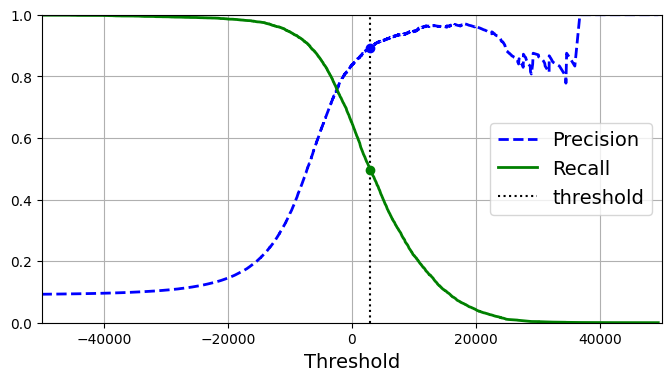

In [41]:
plt.figure(figsize=(8, 4))  # extra code – it's not needed, just formatting
plt.plot(thresholds, precisions[:-1], "b--", label="Precision", linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall", linewidth=2)
plt.vlines(threshold, 0, 1.0, "k", "dotted", label="threshold")

# extra code – this section just beautifies Figure 3–5
idx = (thresholds >= threshold).argmax()  # first index ≥ threshold
plt.plot(thresholds[idx], precisions[idx], "bo")
plt.plot(thresholds[idx], recalls[idx], "go")
plt.axis([-50000, 50000, 0, 1])
plt.grid()
plt.xlabel("Threshold")
plt.legend(loc="center right")

plt.show()

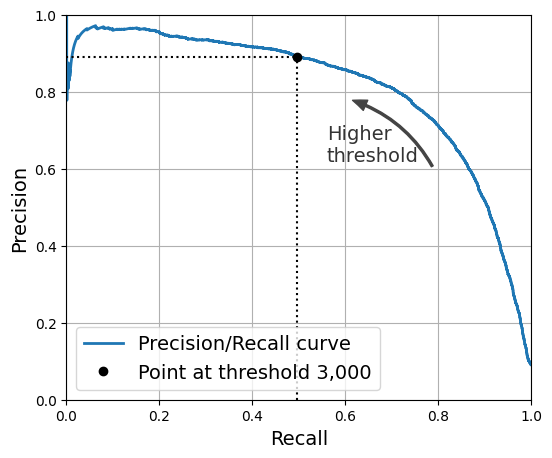

In [42]:
import matplotlib.patches as patches  # extra code – for the curved arrow

plt.figure(figsize=(6, 5))  # extra code – not needed, just formatting

plt.plot(recalls, precisions, linewidth=2, label="Precision/Recall curve")

# extra code – just beautifies Figure 3–6
plt.plot([recalls[idx], recalls[idx]], [0., precisions[idx]], "k:")
plt.plot([0.0, recalls[idx]], [precisions[idx], precisions[idx]], "k:")
plt.plot([recalls[idx]], [precisions[idx]], "ko",
         label="Point at threshold 3,000")
plt.gca().add_patch(patches.FancyArrowPatch(
    (0.79, 0.60), (0.61, 0.78),
    connectionstyle="arc3,rad=.2",
    arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10",
    color="#444444"))
plt.text(0.56, 0.62, "Higher\nthreshold", color="#333333")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid()
plt.legend(loc="lower left")

plt.show()

In [43]:
idx_for_90_precision = (precisions >= 0.90).argmax()
threshold_for_90_precision = thresholds[idx_for_90_precision]
threshold_for_90_precision

np.float64(3370.0194991439557)

In [44]:
y_train_pred_90 = (y_scores >= threshold_for_90_precision)

In [45]:
precision_score(y_train_5, y_train_pred_90)

0.9000345901072293

In [46]:
recall_at_90_precision = recall_score(y_train_5, y_train_pred_90)
recall_at_90_precision

0.4799852425751706

In [47]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

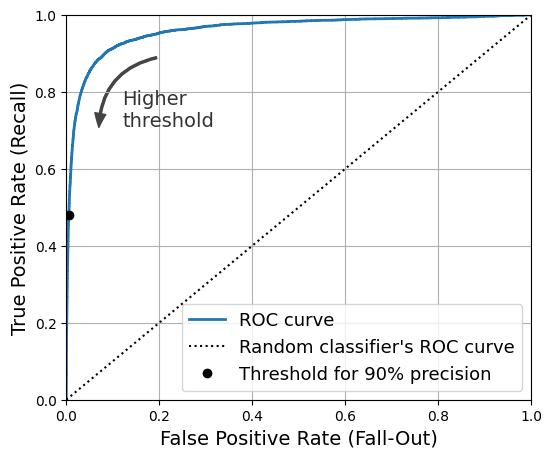

In [48]:
idx_for_threshold_at_90 = (thresholds <= threshold_for_90_precision).argmax()
tpr_90, fpr_90 = tpr[idx_for_threshold_at_90], fpr[idx_for_threshold_at_90]

plt.figure(figsize=(6, 5))  # extra code – not needed, just formatting
plt.plot(fpr, tpr, linewidth=2, label="ROC curve")
plt.plot([0, 1], [0, 1], 'k:', label="Random classifier's ROC curve")
plt.plot([fpr_90], [tpr_90], "ko", label="Threshold for 90% precision")

# extra code – just beautifies Figure 3–7
plt.gca().add_patch(patches.FancyArrowPatch(
    (0.20, 0.89), (0.07, 0.70),
    connectionstyle="arc3,rad=.4",
    arrowstyle="Simple, tail_width=1.5, head_width=8, head_length=10",
    color="#444444"))
plt.text(0.12, 0.71, "Higher\nthreshold", color="#333333")
plt.xlabel('False Positive Rate (Fall-Out)')
plt.ylabel('True Positive Rate (Recall)')
plt.grid()
plt.axis([0, 1, 0, 1])
plt.legend(loc="lower right", fontsize=13)

plt.show()

In [49]:
print("TPR:", tpr_90)
print("FPR:", fpr_90)

TPR: 0.4799852425751706
FPR: 0.005295076861063779


In [50]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_train_5, y_scores)

np.float64(0.9604938554008616)

In [51]:
from sklearn.ensemble import RandomForestClassifier

forest_clf = RandomForestClassifier(random_state=42)

In [52]:
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_5, cv=3,
                                    method="predict_proba")

In [53]:
y_probas_forest[:2]

array([[0.11, 0.89],
       [0.99, 0.01]])

In [54]:
# Not in the code
idx_50_to_60 = (y_probas_forest[:, 1] > 0.50) & (y_probas_forest[:, 1] < 0.60)
print(f"{(y_train_5[idx_50_to_60]).sum() / idx_50_to_60.sum():.1%}")

94.0%


In [55]:
y_scores_forest = y_probas_forest[:, 1]
precisions_forest, recalls_forest, thresholds_forest = precision_recall_curve(
    y_train_5, y_scores_forest)

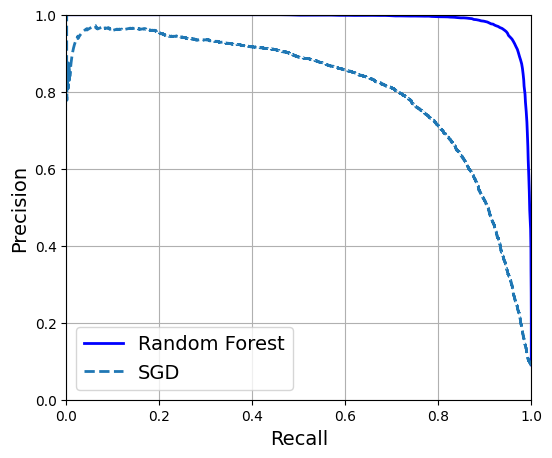

In [56]:
plt.figure(figsize=(6, 5))  # extra code – not needed, just formatting

plt.plot(recalls_forest, precisions_forest, "b-", linewidth=2,
         label="Random Forest")
plt.plot(recalls, precisions, "--", linewidth=2, label="SGD")

# extra code – just beautifies Figure 3–8
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.axis([0, 1, 0, 1])
plt.grid()
plt.legend(loc="lower left")

plt.show()

In [57]:
y_train_pred_forest = y_probas_forest[:, 1] > 0.5  # positive proba >50%
f1_score(y_train_5, y_train_pred_forest)

0.9242275142688448

In [58]:
roc_auc_score(y_train_5, y_scores_forest)

np.float64(0.9983436731328145)

In [59]:
precision_score(y_train_5, y_train_pred_forest)

0.9905083315756169

In [60]:
recall_score(y_train_5, y_train_pred_forest)

0.8662608374838591

In [61]:
from sklearn.svm import SVC

svm_clf = SVC(random_state=42)
svm_clf.fit(X_train[:2000], y_train[:2000])  # y_train, not y_train_5

SVC(random_state=42)

In [62]:
svm_clf.predict([some_digit])

array(['5'], dtype=object)

In [63]:
some_digit_scores = svm_clf.decision_function([some_digit])
some_digit_scores.round(2)

array([[ 3.79,  0.73,  6.06,  8.3 , -0.29,  9.3 ,  1.75,  2.77,  7.21,
         4.82]])

In [64]:
class_id = some_digit_scores.argmax()
class_id

np.int64(5)

In [65]:
svm_clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)

In [66]:
svm_clf.classes_[class_id]

'5'

In [67]:
# extra code – shows how to get all 45 OvO scores if needed
svm_clf.decision_function_shape = "ovo"
some_digit_scores_ovo = svm_clf.decision_function([some_digit])
some_digit_scores_ovo.round(2)

array([[ 0.11, -0.21, -0.97,  0.51, -1.01,  0.19,  0.09, -0.31, -0.04,
        -0.45, -1.28,  0.25, -1.01, -0.13, -0.32, -0.9 , -0.36, -0.93,
         0.79, -1.  ,  0.45,  0.24, -0.24,  0.25,  1.54, -0.77,  1.11,
         1.13,  1.04,  1.2 , -1.42, -0.53, -0.45, -0.99, -0.95,  1.21,
         1.  ,  1.  ,  1.08, -0.02, -0.67, -0.14, -0.3 , -0.13,  0.25]])

In [68]:
from sklearn.multiclass import OneVsRestClassifier

ovr_clf = OneVsRestClassifier(SVC(random_state=42))
ovr_clf.fit(X_train[:2000], y_train[:2000])

OneVsRestClassifier(estimator=SVC(random_state=42))

In [69]:
ovr_clf.predict([some_digit])

array(['5'], dtype='<U1')

In [70]:
len(ovr_clf.estimators_)

10

In [71]:
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train)
sgd_clf.predict([some_digit])

array(['3'], dtype='<U1')

In [72]:
sgd_clf.decision_function([some_digit]).round()

array([[-31893., -34420.,  -9531.,   1824., -22320.,  -1386., -26189.,
        -16148.,  -4604., -12051.]])

In [73]:
cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy")

array([0.87365, 0.85835, 0.8689 ])

In [74]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype("float64"))
cross_val_score(sgd_clf, X_train_scaled, y_train, cv=3, scoring="accuracy")

array([0.8983, 0.891 , 0.9018])

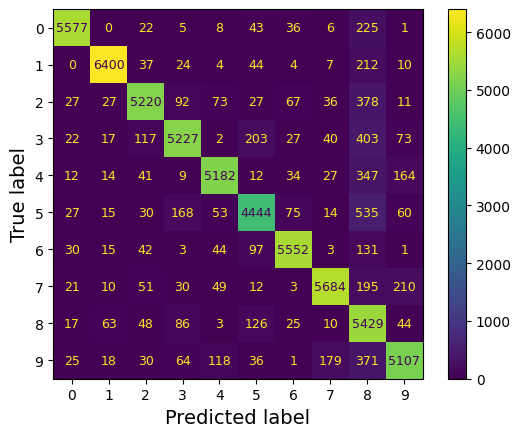

In [76]:
from sklearn.metrics import ConfusionMatrixDisplay

y_train_pred = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3)
plt.rc('font', size=9)  # extra code – make the text smaller
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
plt.show()

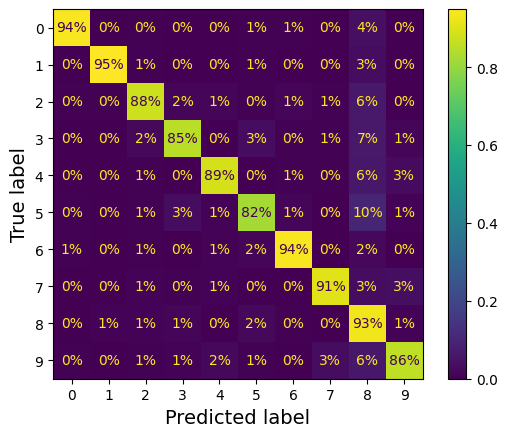

In [77]:
plt.rc('font', size=10)  # extra code
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred,
                                        normalize="true", values_format=".0%")
plt.show()

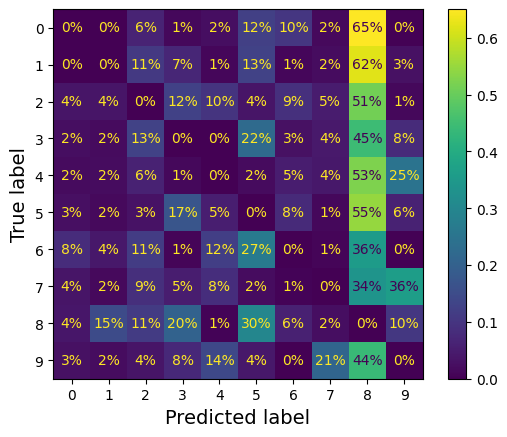

In [78]:
sample_weight = (y_train_pred != y_train)
plt.rc('font', size=10)  # extra code
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred,
                                        sample_weight=sample_weight,
                                        normalize="true", values_format=".0%")
plt.show()

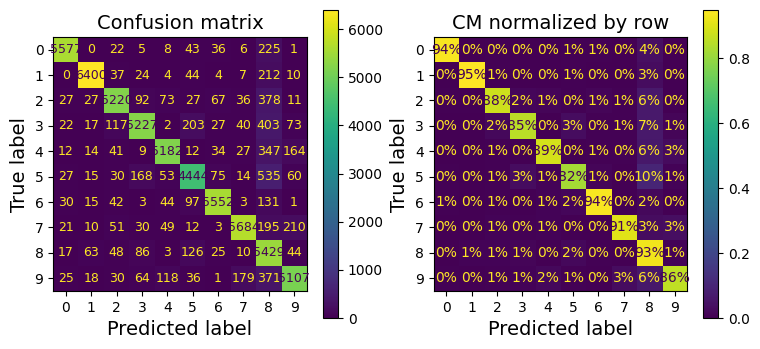

In [79]:
# extra code – this cell generates Figure 3–9
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 4))
plt.rc('font', size=9)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axs[0])
axs[0].set_title("Confusion matrix")
plt.rc('font', size=10)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axs[1],
                                        normalize="true", values_format=".0%")
axs[1].set_title("CM normalized by row")

plt.show()

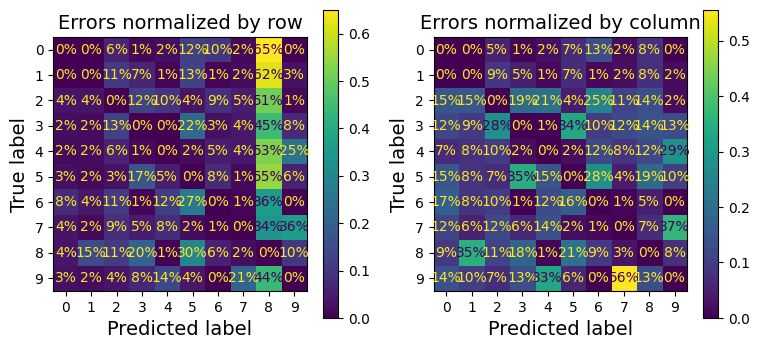

In [81]:
# extra code – this cell generates Figure 3–10
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 4))
plt.rc('font', size=10)
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axs[0],
                                        sample_weight=sample_weight,
                                        normalize="true", values_format=".0%")
axs[0].set_title("Errors normalized by row")
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred, ax=axs[1],
                                        sample_weight=sample_weight,
                                        normalize="pred", values_format=".0%")
axs[1].set_title("Errors normalized by column")

plt.show()
plt.rc('font', size=14)  # make fonts great again

In [82]:
cl_a, cl_b = '7', '9'
X_aa = X_train[(y_train == cl_a) & (y_train_pred == cl_a)]
X_ab = X_train[(y_train == cl_a) & (y_train_pred == cl_b)]
X_ba = X_train[(y_train == cl_b) & (y_train_pred == cl_a)]
X_bb = X_train[(y_train == cl_b) & (y_train_pred == cl_b)]

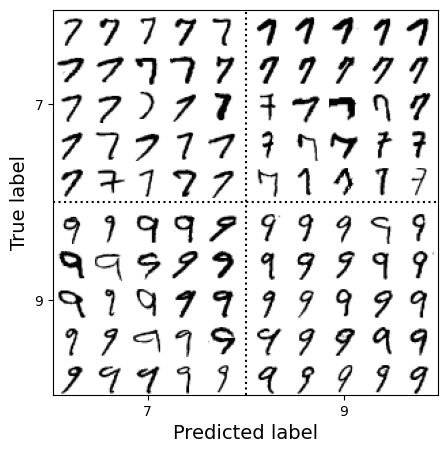

In [83]:
# extra code – this cell generates Figure 3–11
size = 5
pad = 0.2
plt.figure(figsize=(size, size))
for images, (label_col, label_row) in [(X_ba, (0, 0)), (X_bb, (1, 0)),
                                       (X_aa, (0, 1)), (X_ab, (1, 1))]:
    for idx, image_data in enumerate(images[:size*size]):
        x = idx % size + label_col * (size + pad)
        y = idx // size + label_row * (size + pad)
        plt.imshow(image_data.reshape(28, 28), cmap="binary",
                   extent=(x, x + 1, y, y + 1))
plt.xticks([size / 2, size + pad + size / 2], [str(cl_a), str(cl_b)])
plt.yticks([size / 2, size + pad + size / 2], [str(cl_b), str(cl_a)])
plt.plot([size + pad / 2, size + pad / 2], [0, 2 * size + pad], "k:")
plt.plot([0, 2 * size + pad], [size + pad / 2, size + pad / 2], "k:")
plt.axis([0, 2 * size + pad, 0, 2 * size + pad])
plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.show()

In [84]:
cl_a, cl_b = '3', '5'
X_aa = X_train[(y_train == cl_a) & (y_train_pred == cl_a)]
X_ab = X_train[(y_train == cl_a) & (y_train_pred == cl_b)]
X_ba = X_train[(y_train == cl_b) & (y_train_pred == cl_a)]
X_bb = X_train[(y_train == cl_b) & (y_train_pred == cl_b)]

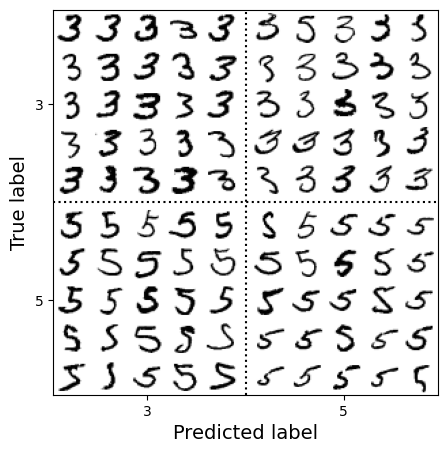

In [85]:
# extra code – this cell generates Figure 3–11
size = 5
pad = 0.2
plt.figure(figsize=(size, size))
for images, (label_col, label_row) in [(X_ba, (0, 0)), (X_bb, (1, 0)),
                                       (X_aa, (0, 1)), (X_ab, (1, 1))]:
    for idx, image_data in enumerate(images[:size*size]):
        x = idx % size + label_col * (size + pad)
        y = idx // size + label_row * (size + pad)
        plt.imshow(image_data.reshape(28, 28), cmap="binary",
                   extent=(x, x + 1, y, y + 1))
plt.xticks([size / 2, size + pad + size / 2], [str(cl_a), str(cl_b)])
plt.yticks([size / 2, size + pad + size / 2], [str(cl_b), str(cl_a)])
plt.plot([size + pad / 2, size + pad / 2], [0, 2 * size + pad], "k:")
plt.plot([0, 2 * size + pad], [size + pad / 2, size + pad / 2], "k:")
plt.axis([0, 2 * size + pad, 0, 2 * size + pad])
plt.xlabel("Predicted label")
plt.ylabel("True label")

plt.show()

In [86]:
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

y_train_large = (y_train >= '7')
y_train_odd = (y_train.astype('int8') % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]

knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train, y_multilabel)

KNeighborsClassifier()

In [87]:
knn_clf.predict([some_digit])

array([[False,  True]])

In [88]:
y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_multilabel, cv=3)
f1_score(y_multilabel, y_train_knn_pred, average="macro")

0.9764102655606048

In [89]:
# extra code – shows that we get a negligible performance improvement when we
#              set average="weighted" because the classes are already pretty
#              well balanced.
f1_score(y_multilabel, y_train_knn_pred, average="weighted")

0.9778357403921755

In [90]:
from sklearn.multioutput import ClassifierChain

chain_clf = ClassifierChain(SVC(), cv=3, random_state=42)
chain_clf.fit(X_train[:2000], y_multilabel[:2000])

ClassifierChain(base_estimator=SVC(), cv=3, random_state=42)

In [91]:
chain_clf.predict([some_digit])

array([[0., 1.]])

In [92]:
rng = np.random.default_rng(seed=42)  # to make this code example reproducible
noise_train = rng.integers(0, 100, (len(X_train), 784))
X_train_mod = X_train + noise_train
noise_test = rng.integers(0, 100, (len(X_test), 784))
X_test_mod = X_test + noise_test
y_train_mod = X_train
y_test_mod = X_test

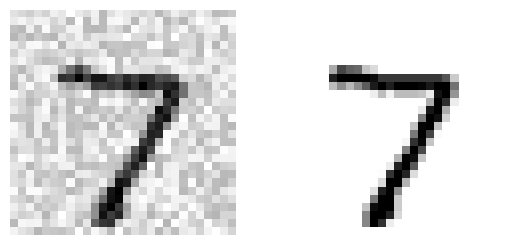

In [93]:
# extra code – this cell generates Figure 3–12
plt.subplot(121); plot_digit(X_test_mod[0])
plt.subplot(122); plot_digit(y_test_mod[0])

plt.show()

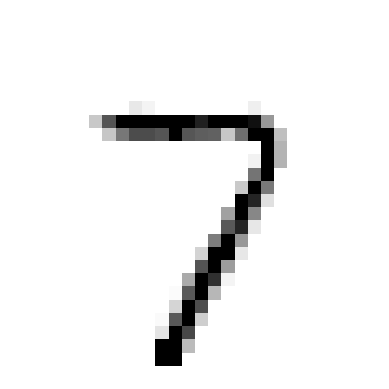

In [94]:
knn_clf = KNeighborsClassifier()
knn_clf.fit(X_train_mod, y_train_mod)
clean_digit = knn_clf.predict([X_test_mod[0]])
plot_digit(clean_digit)

plt.show()

EX #1

In [95]:
# Use the MNIST dataset already loaded earlier in the notebook.
ex1_X_train = mnist.data[:60000]
ex1_X_test = mnist.data[60000:]

ex1_y_train = mnist.target[:60000]
ex1_y_test = mnist.target[60000:]

print("Training images:", ex1_X_train.shape)
print("Test images:", ex1_X_test.shape)

Training images: (60000, 784)
Test images: (10000, 784)


In [96]:
from sklearn.neighbors import KNeighborsClassifier

ex1_baseline_clf = KNeighborsClassifier()
ex1_baseline_clf.fit(ex1_X_train, ex1_y_train)

ex1_baseline_accuracy = ex1_baseline_clf.score(
    ex1_X_test, ex1_y_test
)

print(f"Baseline test accuracy: {ex1_baseline_accuracy:.2%}")

Baseline test accuracy: 96.88%


In [97]:
from sklearn.model_selection import GridSearchCV

ex1_param_grid = {
    "n_neighbors": [3, 4, 5, 6],
    "weights": ["uniform", "distance"]
}

ex1_grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=ex1_param_grid,
    scoring="accuracy",
    cv=3
)

In [100]:
ex1_grid_search.fit(
    ex1_X_train[:20_000],
    ex1_y_train[:20_000]
)

print("Best parameters:", ex1_grid_search.best_params_)
print(
    f"Best cross-validation accuracy: "
    f"{ex1_grid_search.best_score_:.2%}"
)

Best parameters: {'n_neighbors': 3, 'weights': 'distance'}
Best cross-validation accuracy: 95.33%


In [101]:
ex1_best_knn_clf = ex1_grid_search.best_estimator_

ex1_best_knn_clf.fit(ex1_X_train, ex1_y_train)

ex1_tuned_accuracy = ex1_best_knn_clf.score(
    ex1_X_test, ex1_y_test
)

print(f"Tuned test accuracy: {ex1_tuned_accuracy:.2%}")
print(f"Above 97%: {ex1_tuned_accuracy > 0.97}")

Tuned test accuracy: 97.17%
Above 97%: True


EX #2

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import shift

def ex2_shift_image(image, dx, dy):
    image_2d = image.reshape(28, 28)

    shifted_image = shift(
        image_2d,
        shift=[dy, dx],
        order=0,
        mode="constant",
        cval=0
    )

    return shifted_image.reshape(-1)

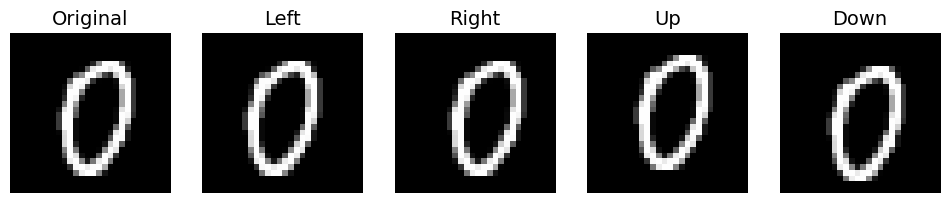

In [103]:
ex2_example = ex1_X_train[1000]

ex2_examples = [
    ("Original", ex2_example),
    ("Left", ex2_shift_image(ex2_example, -1, 0)),
    ("Right", ex2_shift_image(ex2_example, 1, 0)),
    ("Up", ex2_shift_image(ex2_example, 0, -1)),
    ("Down", ex2_shift_image(ex2_example, 0, 1))
]

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for ax, (title, image) in zip(axes, ex2_examples):
    ax.imshow(image.reshape(28, 28), cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.show()

In [104]:
ex2_directions = [
    (-1, 0),   # left
    (1, 0),    # right
    (0, -1),   # up
    (0, 1)     # down
]

ex2_n_train = len(ex1_X_train)

ex2_X_train_augmented = np.empty(
    (5 * ex2_n_train, 784),
    dtype=ex1_X_train.dtype
)

ex2_y_train_augmented = np.empty(
    5 * ex2_n_train,
    dtype=ex1_y_train.dtype
)

# First, keep the original images and labels.
ex2_X_train_augmented[:ex2_n_train] = ex1_X_train
ex2_y_train_augmented[:ex2_n_train] = ex1_y_train

# Then, add one block of shifted images for each direction.
for block, (dx, dy) in enumerate(ex2_directions, start=1):
    start = block * ex2_n_train
    end = start + ex2_n_train

    for i, image in enumerate(ex1_X_train):
        ex2_X_train_augmented[start + i] = ex2_shift_image(
            image, dx, dy
        )

    ex2_y_train_augmented[start:end] = ex1_y_train

print("Expanded images:", ex2_X_train_augmented.shape)
print("Expanded labels:", ex2_y_train_augmented.shape)

Expanded images: (300000, 784)
Expanded labels: (300000,)


In [105]:
from sklearn.neighbors import KNeighborsClassifier

ex2_knn_clf = KNeighborsClassifier(
    **ex1_grid_search.best_params_
)

print("Selected settings:", ex1_grid_search.best_params_)

ex2_knn_clf.fit(
    ex2_X_train_augmented,
    ex2_y_train_augmented
)

Selected settings: {'n_neighbors': 3, 'weights': 'distance'}


KNeighborsClassifier(n_neighbors=3, weights='distance')

In [106]:
ex2_augmented_accuracy = ex2_knn_clf.score(
    ex1_X_test,
    ex1_y_test
)

print(f"Exercise 1 accuracy: {ex1_tuned_accuracy:.2%}")
print(f"Augmented accuracy:  {ex2_augmented_accuracy:.2%}")

ex2_gain = 100 * (
    ex2_augmented_accuracy - ex1_tuned_accuracy
)

print(f"Change: {ex2_gain:+.2f} percentage points")

Exercise 1 accuracy: 97.17%
Augmented accuracy:  97.63%
Change: +0.46 percentage points


Ex #3

In [107]:
from pathlib import Path
import tarfile
import urllib.request
import pandas as pd

def ex3_load_titanic_data():
    data_dir = Path("datasets/titanic")
    train_path = data_dir / "train.csv"
    test_path = data_dir / "test.csv"

    if not (train_path.is_file() and test_path.is_file()):
        archive_path = Path("datasets/titanic.tgz")
        archive_path.parent.mkdir(parents=True, exist_ok=True)

        if not archive_path.is_file():
            urllib.request.urlretrieve(
                "https://github.com/ageron/data/raw/main/titanic.tgz",
                archive_path
            )

        with tarfile.open(archive_path) as archive:
            archive.extractall(path="datasets", filter="data")

    return (
        pd.read_csv(train_path, index_col="PassengerId"),
        pd.read_csv(test_path, index_col="PassengerId")
    )

ex3_train_data, ex3_test_data = ex3_load_titanic_data()

print("Training data:", ex3_train_data.shape)
print("Test data:", ex3_test_data.shape)

ex3_train_data.head()

Training data: (891, 11)
Test data: (418, 10)


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [108]:
ex3_train_data.info()

print("\nMissing values:")
print(ex3_train_data.isna().sum())

print("\nTarget counts:")
print(ex3_train_data["Survived"].value_counts())

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB

Missing values:
Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Ticket        0
Fare          0
Cabin       687
Embarked      2
dtype: int64

Target counts:
Survived
0    549
1    342
Name: count, dtype: int64


In [109]:
ex3_X_train = ex3_train_data.drop(columns="Survived")
ex3_y_train = ex3_train_data["Survived"]

ex3_X_test = ex3_test_data.copy()

In [110]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

ex3_num_features = ["Age", "SibSp", "Parch", "Fare"]
ex3_cat_features = ["Pclass", "Sex", "Embarked"]

ex3_num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

ex3_cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

ex3_preprocessor = ColumnTransformer([
    ("num", ex3_num_pipeline, ex3_num_features),
    ("cat", ex3_cat_pipeline, ex3_cat_features)
])

In [111]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

ex3_models = {
    "Random forest": Pipeline([
        ("preprocessor", clone(ex3_preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ]),
    "SVM": Pipeline([
        ("preprocessor", clone(ex3_preprocessor)),
        ("classifier", SVC(gamma="auto"))
    ])
}

ex3_cv = StratifiedKFold(n_splits=10)

ex3_cv_scores = {}

for ex3_name, ex3_pipeline in ex3_models.items():
    ex3_scores = cross_val_score(
        ex3_pipeline,
        ex3_X_train,
        ex3_y_train,
        cv=ex3_cv,
        scoring="accuracy"
    )

    ex3_cv_scores[ex3_name] = ex3_scores

    print(
        f"{ex3_name}: "
        f"mean accuracy = {ex3_scores.mean():.2%}, "
        f"fold standard deviation = {ex3_scores.std():.2%}"
    )

Random forest: mean accuracy = 81.04%, fold standard deviation = 4.43%
SVM: mean accuracy = 82.61%, fold standard deviation = 3.18%


In [112]:
ex3_majority_accuracy = (
    ex3_y_train.value_counts(normalize=True).max()
)

print(f"Majority-class baseline: {ex3_majority_accuracy:.2%}")

Majority-class baseline: 61.62%


In [113]:
ex3_best_name = max(
    ex3_cv_scores,
    key=lambda name: ex3_cv_scores[name].mean()
)

ex3_best_model = clone(ex3_models[ex3_best_name])

ex3_best_model.fit(ex3_X_train, ex3_y_train)

print("Selected model:", ex3_best_name)

Selected model: SVM


In [114]:
ex3_test_predictions = ex3_best_model.predict(ex3_X_test)

ex3_submission = pd.DataFrame({
    "PassengerId": ex3_X_test.index,
    "Survived": ex3_test_predictions
})

print(ex3_submission.head())
print("Number of predictions:", len(ex3_submission))

   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1
Number of predictions: 418


In [115]:
ex3_submission.to_csv(
    "titanic_submission.csv",
    index=False
)

Ex #4

In [1]:
from pathlib import Path
import urllib.request
import tarfile

def ex4_fetch_email_data():
    root = Path("datasets/spam")
    root.mkdir(parents=True, exist_ok=True)

    base_url = "https://spamassassin.apache.org/old/publiccorpus/"

    archives = [
        ("easy_ham", "20030228_easy_ham.tar.bz2"),
        ("spam", "20030228_spam.tar.bz2")
    ]

    for folder, filename in archives:
        if not (root / folder).is_dir():
            archive_path = root / filename

            if not archive_path.is_file():
                print("Downloading:", filename)
                urllib.request.urlretrieve(
                    base_url + filename,
                    archive_path
                )

            with tarfile.open(archive_path, "r:bz2") as archive:
                archive.extractall(path=root, filter="data")

    return root / "easy_ham", root / "spam"

ex4_ham_dir, ex4_spam_dir = ex4_fetch_email_data()

Downloading: 20030228_easy_ham.tar.bz2
Downloading: 20030228_spam.tar.bz2


In [2]:
from email import policy
from email.parser import BytesParser

def ex4_load_email(path):
    with path.open("rb") as file:
        return BytesParser(policy=policy.default).parse(file)

ex4_ham_files = [
    path for path in sorted(ex4_ham_dir.iterdir())
    if path.is_file() and len(path.name) > 20
]

ex4_spam_files = [
    path for path in sorted(ex4_spam_dir.iterdir())
    if path.is_file() and len(path.name) > 20
]

ex4_ham_emails = [
    ex4_load_email(path) for path in ex4_ham_files
]

ex4_spam_emails = [
    ex4_load_email(path) for path in ex4_spam_files
]

print("Ham emails:", len(ex4_ham_emails))
print("Spam emails:", len(ex4_spam_emails))

Ham emails: 2500
Spam emails: 500


In [3]:
import numpy as np
from sklearn.model_selection import train_test_split

# Allocate a one-dimensional object array for the parsed emails.
ex4_X = np.empty(
    len(ex4_ham_emails) + len(ex4_spam_emails),
    dtype=object
)
ex4_X[:] = ex4_ham_emails + ex4_spam_emails

ex4_y = np.array(
    [0] * len(ex4_ham_emails)
    + [1] * len(ex4_spam_emails)
)

ex4_X_train, ex4_X_test, ex4_y_train, ex4_y_test = (
    train_test_split(
        ex4_X,
        ex4_y,
        test_size=0.2,
        stratify=ex4_y,
        random_state=42
    )
)

print("Training emails:", len(ex4_X_train))
print("Test emails:", len(ex4_X_test))

Training emails: 2400
Test emails: 600


In [4]:
import re
from html import unescape

def ex4_html_to_text(html):
    # Remove sections that are not visible body text.
    text = re.sub(
        r"<(head|script|style)\b[^>]*>.*?</\1\s*>",
        " ",
        html,
        flags=re.IGNORECASE | re.DOTALL
    )

    # Preserve an indication that a link was present.
    text = re.sub(
        r"<a\b[^>]*>",
        " HYPERLINK ",
        text,
        flags=re.IGNORECASE
    )

    # Remove remaining HTML tags.
    text = re.sub(r"<[^>]+>", " ", text)

    return unescape(text)


def ex4_email_to_text(message):
    plain_parts = []
    html_parts = []

    for part in message.walk():
        if part.get_content_disposition() == "attachment":
            continue

        content_type = part.get_content_type()

        if content_type not in ("text/plain", "text/html"):
            continue

        try:
            content = part.get_content()
        except (LookupError, UnicodeError):
            payload = part.get_payload(decode=True)
            content = (
                payload.decode("utf-8", errors="replace")
                if isinstance(payload, bytes)
                else str(part.get_payload())
            )

        if not isinstance(content, str):
            continue

        if content_type == "text/plain":
            plain_parts.append(content)
        else:
            html_parts.append(content)

    if plain_parts:
        return "\n".join(plain_parts)

    return "\n".join(
        ex4_html_to_text(html) for html in html_parts
    )

In [5]:
print("Subject:", ex4_X_train[0].get("Subject"))
print()
print(ex4_email_to_text(ex4_X_train[0])[:1000])

Subject: Re: Canadians

>>>>> "R" == Russell Turpin <deafbox@hotmail.com> writes:

    R> Things aren't all that bad. I remember Vancouver as having a
    R> broad variety of good, local eateries.  And Toronto as having a
    R> variety of good, local strip joints. ;-) 

I haven't been to Van in years, but I do know that in Toronto, outside
of the small deeply ethnic neighbourhoods, if you stray more than 50
feet from Wellesley and Jarvis or Queen and Spadina, you're in
doughnutland; there's far more like the eateries in the Eaton Centre
than there are quaint cafes like McCaul north of Dundas, and the rare
little eateries are not brimming with lunchtime traffic (you can still
find a seat at noon at Village by the Grange)

When most of Toronto does not live in those neighbourhoods but instead
lives in Scarborough, Malton, Mississauga and Markham (franchisevilles), you
will quickly see that one or two trendy strips does not save an entire
nation.


-- 
Gary Lawrence Murphy <garym@teledyn

In [6]:
from sklearn.base import BaseEstimator, TransformerMixin

class Ex4EmailToTextTransformer(BaseEstimator, TransformerMixin):
    def __init__(
        self,
        strip_headers=True,
        lower_case=True,
        replace_urls=True,
        replace_numbers=True,
        remove_punctuation=True
    ):
        self.strip_headers = strip_headers
        self.lower_case = lower_case
        self.replace_urls = replace_urls
        self.replace_numbers = replace_numbers
        self.remove_punctuation = remove_punctuation

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        cleaned_emails = []

        for message in X:
            text = ex4_email_to_text(message)

            if not self.strip_headers:
                headers = "\n".join(
                    f"{key}: {value}"
                    for key, value in message.items()
                )
                text = headers + "\n" + text

            if self.replace_urls:
                text = re.sub(
                    r"(?:https?://|www\.)\S+",
                    " URL ",
                    text,
                    flags=re.IGNORECASE
                )

            if self.replace_numbers:
                text = re.sub(
                    r"\d+(?:[.,]\d+)*",
                    " NUMBER ",
                    text
                )

            if self.lower_case:
                text = text.lower()

            if self.remove_punctuation:
                text = re.sub(r"[\W_]+", " ", text)

            cleaned_emails.append(text)

        return cleaned_emails

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

ex4_demo_vectorizer = CountVectorizer(
    vocabulary=["hello", "how", "are", "you"]
)

ex4_demo_vector = ex4_demo_vectorizer.fit_transform([
    "Hello you Hello Hello you"
])

print(ex4_demo_vectorizer.get_feature_names_out())
print(ex4_demo_vector.toarray())

['hello' 'how' 'are' 'you']
[[3 0 0 2]]


In [8]:
ex4_demo_binary = CountVectorizer(
    vocabulary=["hello", "how", "are", "you"],
    binary=True
)

print(
    ex4_demo_binary.fit_transform(
        ["Hello you Hello Hello you"]
    ).toarray()
)

[[1 0 0 1]]


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import StratifiedKFold, cross_validate

def ex4_make_pipeline(classifier):
    return Pipeline([
        ("cleaner", Ex4EmailToTextTransformer()),
        ("vectorizer", CountVectorizer(
            max_features=1000,
            lowercase=False,
            tokenizer=str.split,
            token_pattern=None
        )),
        ("classifier", classifier)
    ])

ex4_models = {
    "Logistic regression": ex4_make_pipeline(
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Naive Bayes": ex4_make_pipeline(
        MultinomialNB()
    )
}

ex4_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

ex4_cv_results = {}

for ex4_name, ex4_model in ex4_models.items():
    ex4_result = cross_validate(
        ex4_model,
        ex4_X_train,
        ex4_y_train,
        cv=ex4_cv,
        scoring=["accuracy", "precision", "recall", "f1"]
    )

    ex4_cv_results[ex4_name] = ex4_result

    print(ex4_name)
    for ex4_metric in ["accuracy", "precision", "recall", "f1"]:
        print(
            f"  {ex4_metric}: "
            f"{ex4_result['test_' + ex4_metric].mean():.2%}"
        )
    print()

Logistic regression
  accuracy: 98.79%
  precision: 98.45%
  recall: 94.26%
  f1: 96.29%

Naive Bayes
  accuracy: 94.25%
  precision: 79.87%
  recall: 90.26%
  f1: 84.45%



In [10]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

ex4_best_name = max(
    ex4_cv_results,
    key=lambda name: (
        ex4_cv_results[name]["test_f1"].mean()
    )
)

ex4_best_model = clone(ex4_models[ex4_best_name])
ex4_best_model.fit(ex4_X_train, ex4_y_train)

ex4_y_pred = ex4_best_model.predict(ex4_X_test)

print("Selected model:", ex4_best_name)
print(f"Test accuracy:  {accuracy_score(ex4_y_test, ex4_y_pred):.2%}")
print(f"Test precision: {precision_score(ex4_y_test, ex4_y_pred):.2%}")
print(f"Test recall:    {recall_score(ex4_y_test, ex4_y_pred):.2%}")
print(f"Test F1:        {f1_score(ex4_y_test, ex4_y_pred):.2%}")

print("\nConfusion matrix:")
print(confusion_matrix(ex4_y_test, ex4_y_pred, labels=[0, 1]))

Selected model: Logistic regression
Test accuracy:  98.67%
Test precision: 100.00%
Test recall:    92.00%
Test F1:        95.83%

Confusion matrix:
[[500   0]
 [  8  92]]


Ex #5

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC

ex5_models = {
    "Logistic regression": ex4_make_pipeline(
        LogisticRegression(max_iter=3000, random_state=42)
    ),
    "Multinomial NB": ex4_make_pipeline(
        MultinomialNB()
    ),
    "Complement NB": ex4_make_pipeline(
        ComplementNB()
    ),
    "Linear SVM": ex4_make_pipeline(
        LinearSVC(max_iter=10000, random_state=42)
    )
}

In [12]:
ex5_param_grids = {
    "Logistic regression": {
        "classifier__C": [0.1, 1, 10]
    },
    "Multinomial NB": {
        "classifier__alpha": [0.1, 1, 10]
    },
    "Complement NB": {
        "classifier__alpha": [0.1, 1, 10]
    },
    "Linear SVM": {
        "classifier__C": [0.01, 0.1, 1]
    }
}

In [15]:
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Normalizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Build the SVM's email-cleaning and word-count pipeline.
ex5_svm_base = ex4_make_pipeline(
    LinearSVC(
        dual=False,
        max_iter=100_000,
        random_state=42
    )
)

# Insert normalization between word counts and the classifier.
ex5_svm_pipeline = Pipeline(
    ex5_svm_base.steps[:-1]
    + [("normalizer", Normalizer(norm="l2"))]
    + [ex5_svm_base.steps[-1]]
)

# Rebuild all models.
ex5_models = {
    "Logistic regression": ex4_make_pipeline(
        LogisticRegression(
            max_iter=3000,
            random_state=42
        )
    ),
    "Multinomial NB": ex4_make_pipeline(
        MultinomialNB()
    ),
    "Complement NB": ex4_make_pipeline(
        ComplementNB()
    ),
    "Linear SVM": ex5_svm_pipeline
}

# Normalization changes the SVM's input scale,
# so search a suitable range of C values again.
ex5_param_grids = {
    "Logistic regression": {
        "classifier__C": [0.1, 1, 10]
    },
    "Multinomial NB": {
        "classifier__alpha": [0.1, 1, 10]
    },
    "Complement NB": {
        "classifier__alpha": [0.1, 1, 10]
    },
    "Linear SVM": {
        "classifier__C": [0.1, 1, 10]
    }
}

ex5_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

ex5_searches = {}
ex5_rows = []

for ex5_name, ex5_pipeline in ex5_models.items():
    print("Searching:", ex5_name)

    ex5_search = GridSearchCV(
        estimator=ex5_pipeline,
        param_grid=ex5_param_grids[ex5_name],
        scoring={
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        refit="f1",
        cv=ex5_cv,
        error_score="raise"
    )

    ex5_search.fit(ex4_X_train, ex4_y_train)
    ex5_searches[ex5_name] = ex5_search

    ex5_best_index = ex5_search.best_index_

    ex5_rows.append({
        "Model": ex5_name,
        "CV precision": ex5_search.cv_results_[
            "mean_test_precision"
        ][ex5_best_index],
        "CV recall": ex5_search.cv_results_[
            "mean_test_recall"
        ][ex5_best_index],
        "CV F1": ex5_search.best_score_,
        "Best settings": ex5_search.best_params_
    })

ex5_results = (
    pd.DataFrame(ex5_rows)
    .set_index("Model")
    .sort_values("CV F1", ascending=False)
)

print("\nModel comparison:")
print(
    ex5_results.to_string(
        formatters={
            "CV precision": "{:.2%}".format,
            "CV recall": "{:.2%}".format,
            "CV F1": "{:.2%}".format
        }
    )
)

Searching: Logistic regression
Searching: Multinomial NB
Searching: Complement NB
Searching: Linear SVM

Model comparison:
                    CV precision CV recall  CV F1               Best settings
Model                                                                        
Logistic regression       98.45%    94.26% 96.29%        {'classifier__C': 1}
Linear SVM                96.90%    93.75% 95.30%       {'classifier__C': 10}
Multinomial NB            80.34%    90.51% 84.84%  {'classifier__alpha': 0.1}
Complement NB             78.14%    91.01% 83.69%  {'classifier__alpha': 0.1}


In [16]:
ex5_best_name = ex5_results.index[0]
ex5_best_search = ex5_searches[ex5_best_name]
ex5_best_model = ex5_best_search.best_estimator_

print("Selected model:", ex5_best_name)
print("Selected settings:", ex5_best_search.best_params_)
print(f"Mean CV F1: {ex5_best_search.best_score_:.2%}")

Selected model: Logistic regression
Selected settings: {'classifier__C': 1}
Mean CV F1: 96.29%


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# The pipeline automatically applies all required preparation,
# including normalization if the SVM was selected.
ex5_y_pred = ex5_best_model.predict(ex4_X_test)

print("Selected model:", ex5_best_name)
print(
    f"Test accuracy:  "
    f"{accuracy_score(ex4_y_test, ex5_y_pred):.2%}"
)
print(
    f"Test precision: "
    f"{precision_score(ex4_y_test, ex5_y_pred):.2%}"
)
print(
    f"Test recall:    "
    f"{recall_score(ex4_y_test, ex5_y_pred):.2%}"
)
print(
    f"Test F1:        "
    f"{f1_score(ex4_y_test, ex5_y_pred):.2%}"
)

ex5_confusion = pd.DataFrame(
    confusion_matrix(
        ex4_y_test,
        ex5_y_pred,
        labels=[0, 1]
    ),
    index=["Actual ham", "Actual spam"],
    columns=["Predicted ham", "Predicted spam"]
)

print("\nConfusion matrix:")
print(ex5_confusion)

Selected model: Logistic regression
Test accuracy:  98.67%
Test precision: 100.00%
Test recall:    92.00%
Test F1:        95.83%

Confusion matrix:
             Predicted ham  Predicted spam
Actual ham             500               0
Actual spam              8              92
